# Measuring an exoplanet's radius and orbital period with TESS
**Target:** HD 118203 b (the benchmark planet of the *Quick fits for TESS light curves* tutorial, exoplanet-case-studies).  
**Pipeline:** SPOC light curve → flatten → Box Least Squares → transit model (batman) + MCMC (emcee) → physical radius.  
Physics: a transit blocks a fraction δ ≈ (R_p/R_★)² of the starlight, so R_p = (R_p/R_★) · R_★; the time between transits is the period P.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent / "code"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import transit_pipeline as tp
cat = pd.read_csv("../data/raw/tess_catalog.csv")
row = cat[cat.pl_name == "HD 118203 b"].iloc[0]
tic = int(row.tic_num)
print("TIC", tic, "| Tmag", row.sy_tmag, "| R* =", row.st_rad, "Rsun | catalog P =", row.pl_orbper, "d | catalog Rp =", round(row.pl_rade, 2), "Rearth")

TIC 286923464 | Tmag 7.4556 | R* = 2.04 Rsun | catalog P = 6.1349779 d | catalog Rp = 12.78 Rearth


## 1. Download the TESS SPOC 2-minute light curve (PDCSAP flux)

sectors used: [15, 16] of 5 available; 29910 points


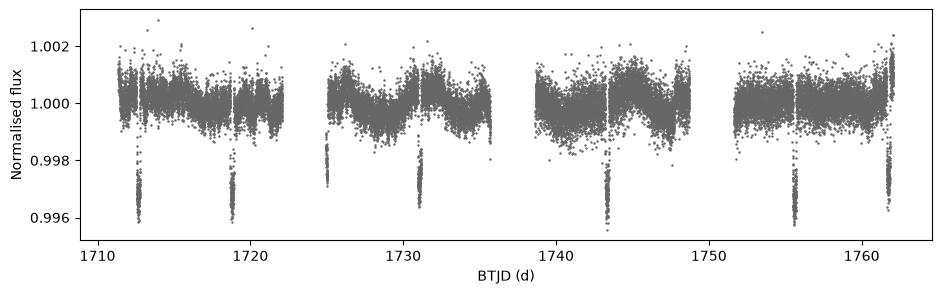

In [2]:
lcs, sectors, n_all = tp.load_lightcurve(tic, max_sectors=4)
print("sectors used:", sectors, "of", n_all, "available;", sum(len(l) for l in lcs), "points")
raw = tp.lk.LightCurveCollection(lcs).stitch()
fig, ax = plt.subplots(figsize=(11, 3)); ax.plot(raw.time.value, raw.flux.value, ".", ms=1.5, color="0.4")
ax.set(xlabel="BTJD (d)", ylabel="Normalised flux"); plt.show()

## 2. Flatten the light curve (remove slow stellar / instrumental trends)
Savitzky–Golay filter, window 1.5 d; outliers clipped at +5σ.

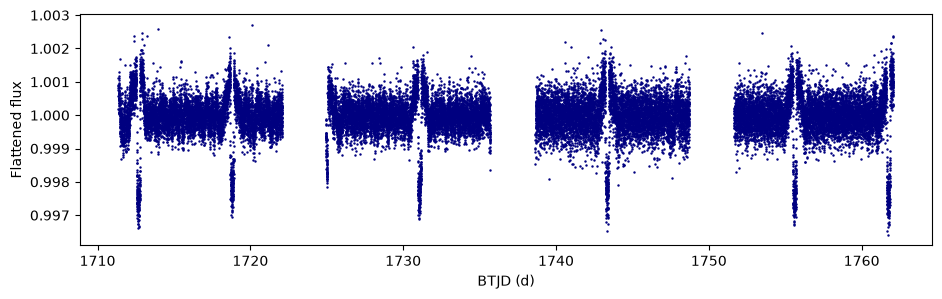

In [3]:
lc = tp.flatten(lcs, 1.5).remove_nans().remove_outliers(sigma_upper=5, sigma_lower=50)
t, f, fe = lc.time.value, lc.flux.value, lc.flux_err.value
fig, ax = plt.subplots(figsize=(11, 3)); ax.plot(t, f, ".", ms=1.5, color="navy"); ax.set(xlabel="BTJD (d)", ylabel="Flattened flux"); plt.show()

## 3. Box Least Squares: find the period, epoch, duration and depth

BLSResult(period=6.135055248581442, t0=1712.6596091599488, duration=0.18, depth_ppm=2296.0992665142394, snr=237.87303392685035)


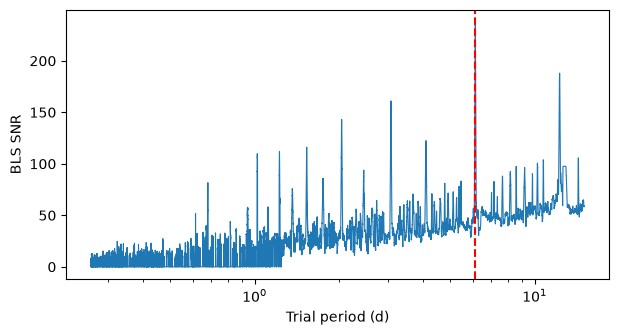

In [4]:
bls, per_grid, power = tp.run_bls(t, f, fe)
print(bls)
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(per_grid, power, lw=0.8); ax.axvline(bls.period, color="r", ls="--")
ax.set(xscale="log", xlabel="Trial period (d)", ylabel="BLS SNR"); plt.show()

## 4. Re-flatten with the transits masked, then fit a physical transit model
Quadratic limb darkening (Kipping q1, q2), circular orbit; parameters t0, P, R_p/R_★, b, a/R_★. MCMC with `emcee`.

In [5]:
msk = tp.in_transit_mask(bls.period, bls.t0, 3.0 * bls.duration)
lc2 = tp.flatten(lcs, max(8 * bls.duration, 1.5), mask=msk).remove_nans().remove_outliers(sigma_upper=5, sigma_lower=50)
fit, chain, (tt, ff, fee, mdl, med) = tp.fit_transit(lc2.time.value, lc2.flux.value, lc2.flux_err.value, bls, nstep=1500)
print(f"P = {fit.period:.5f} +/- {fit.period_err:.5f} d   (catalog {row.pl_orbper:.5f})")
print(f"Rp/R* = {fit.ror:.4f} +/- {fit.ror_err:.4f}   (tutorial: 0.0554)")
print(f"b = {fit.b:.2f},  a/R* = {fit.a_rs:.1f},  {fit.n_transits} transits")

P = 6.13497 +/- 0.00007 d   (catalog 6.13498)
Rp/R* = 0.0553 +/- 0.0003   (tutorial: 0.0554)
b = 0.15,  a/R* = 8.7,  7 transits


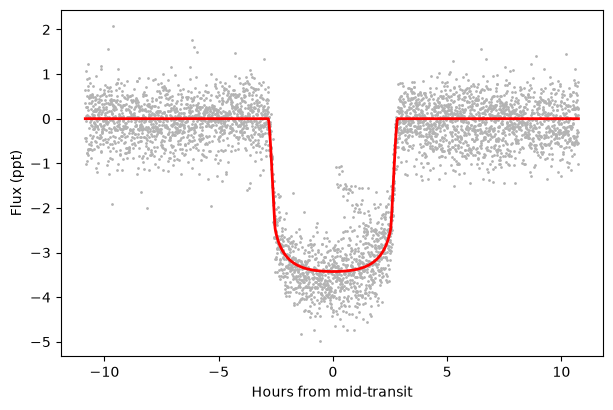

In [6]:
ph = (tt - fit.t0 + 0.5 * fit.period) % fit.period - 0.5 * fit.period
o = np.argsort(ph)
fig, ax = plt.subplots(figsize=(7, 4.5)); ax.plot(ph * 24, (ff - 1) * 1e3, ".", ms=2, color="0.7")
ax.plot(ph[o] * 24, (mdl[o] - 1) * 1e3, color="r", lw=2); ax.set(xlabel="Hours from mid-transit", ylabel="Flux (ppt)"); plt.show()

## 5. From Rp/R★ to a physical radius
The light curve only gives the *ratio*. The stellar radius R★ (from the catalog) converts it into R⊕. Its uncertainty is usually the limiting factor.

In [7]:
rp, rp_err, rj, rj_err = tp.physical_radius(fit, float(row.st_rad), float(row.st_raderr1))
print(f"Rp = {rp:.2f} +/- {rp_err:.2f} Rearth = {rj:.2f} Rjup")
print(f"catalog: {row.pl_rade:.2f} Rearth  ->  difference {100*(rp-row.pl_rade)/row.pl_rade:+.1f} %")
print(f"catalog Rp/R*: {row.pl_ratror:.4f}  ->  difference {100*(fit.ror-row.pl_ratror)/row.pl_ratror:+.1f} %")

Rp = 12.30 +/- 0.19 Rearth = 1.10 Rjup
catalog: 12.78 Rearth  ->  difference -3.8 %
catalog Rp/R*: 0.0557  ->  difference -0.8 %


## 6. Compare with the full 10-planet results
The batch pipeline (`code/04_measure_planet.py`) repeats this for every planet and adds the **systematic error** from three detrending variants (half-range of Rp/R★), quadratically summed with the MCMC error.

In [8]:
import re
rows = []
for n in [l.strip() for l in open("../data/selected.txt") if l.strip()]:
    r = json.load(open("../results/" + re.sub(r"[^A-Za-z0-9]+", "_", n).strip("_") + "/result.json"))
    rows.append(dict(planet=n, mode=r.get("mode", "blind"), P_meas=round(r["fit"]["period"], 5), P_cat=r["catalog"]["period"],
                     ror=round(r["fit"]["ror"], 4), Rp_meas=round(r["rp_rearth"], 2), Rp_err=round(r["rp_rearth_err"], 2),
                     Rp_cat=r["catalog"]["rade"], dRp_pct=round(r["delta_radius_pct"], 1)))
pd.DataFrame(rows)

,planet,mode,P_meas,P_cat,ror,Rp_meas,Rp_err,Rp_cat,dRp_pct
0,HD 118203 b,blind,6.13498,6.134978,0.0553,12.30,0.35,12.778238,-3.8
1,HD 189733 b,blind,2.21858,2.218576,0.1541,12.61,0.18,12.666170,-0.5
2,HD 209458 b,blind,3.52473,3.524749,0.1212,15.74,0.27,15.580510,1.0
3,WASP-18 b,blind,0.94145,0.941452,0.0986,14.18,0.66,13.899136,2.0
4,WASP-62 b,blind,4.41195,4.411950,0.1104,14.82,0.97,14.795880,0.1
5,LTT 9779 b,guided,0.79205,0.792052,0.0440,4.55,0.59,4.720000,-3.6
6,TOI-270 c,blind,5.66023,5.660510,0.0575,2.38,0.07,2.330000,2.3
7,LTT 1445 A b,guided,5.35904,5.358764,0.0470,1.39,0.12,1.340000,3.6
8,GJ 1132 b,blind,1.62891,1.628929,0.0474,1.14,0.05,1.191515,-4.1
9,K2-141 b,guided,0.28041,0.280324,0.0188,1.40,0.10,1.510000,-7.3
